# 03 · Entrenar y guardar el modelo final

En `02_seleccion_modelos.ipynb` se eligió el modelo con validación temporal. Acá:

1. Se entrena **una sola vez** con **todo el train** (campañas 1999/00 – 2019/20).
2. Se mira qué aprendió (qué variables usa).
3. Se **guarda** en `models/modelo_final.joblib` para usarlo en `04_aplicar_test.ipynb` sin volver a entrenar.

**El modelo:** promedio simple (mitad y mitad) de dos modelos que predicen el **desvío del rendimiento en % del nivel esperado** del departamento (target relativo):

| | ElasticNet | CatBoost |
|---|---|---|
| Tipo | lineal regularizado (casi un Lasso) | boosting de árboles |
| Qué capta | el efecto promedio del clima | combinaciones extremas (seco **y** caliente) |
| Variables | estructurales + clima al 10/02 + rezagos | lo mismo + stats del depto, acumulados, promedio provincial e interacciones |

**Nivel esperado** = promedio del departamento + tendencia anual, ambos calculados con el train. Predicción final = nivel esperado × (1 + desvío % predicho).

In [1]:
import json, time, warnings
from datetime import date
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from comun import *

estilo_graficos()
d = cargar()
train = d[d.anio <= ULTIMO_TRAIN].copy()
assert train.anio.max() == ULTIMO_TRAIN and not set(TEST) & set(train.anio), "el test no se usa para entrenar"
print(f"Train: {len(train):,} filas · campañas {train.anio.min()}–{train.anio.max()} · "
      f"{train.departamento_id.nunique()} departamentos")

Train: 4,906 filas · campañas 1999–2019 · 255 departamentos


In [2]:
modelo = modelo_final()
t = time.time()
modelo.fit(train)
print(f"Entrenado en {time.time() - t:.0f} s")
en, cat = modelo.modelos_
print(f"Nivel esperado: tendencia de {en.tend_.b_:+.1f} kg/ha por año")

Entrenado en 34 s
Nivel esperado: tendencia de +32.2 kg/ha por año


## ¿Qué aprendió?

### ElasticNet: coeficientes

Las variables están estandarizadas, así que los coeficientes se pueden comparar entre sí. Un coeficiente de +0.03 significa: *una desviación estándar más de esa variable ⇒ el rinde sube 3 % respecto de lo esperado*.
El ElasticNet (casi un Lasso) pone en **cero** las variables que no aportan.

Variables usadas: 14 de 101 (el resto quedó en cero)


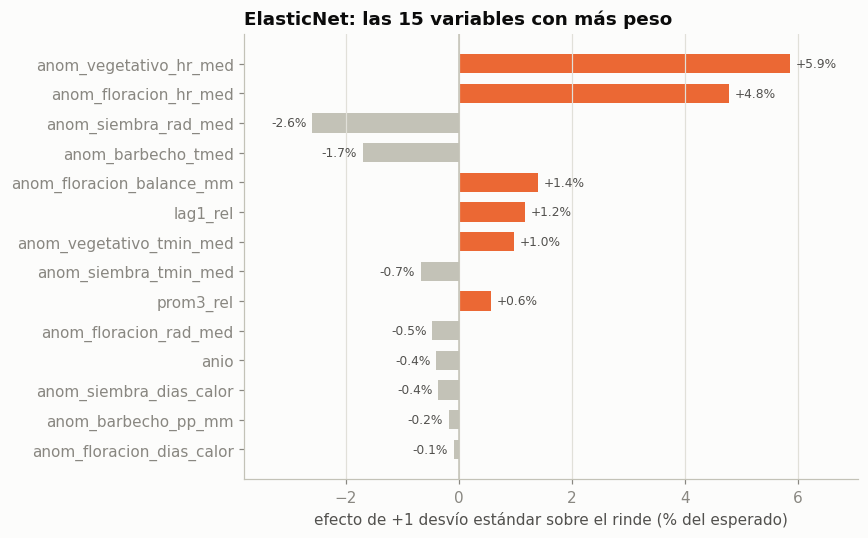

In [3]:
coef = pd.Series(en.est_[-1].coef_, index=en.features_)
print(f"Variables usadas: {(coef != 0).sum()} de {len(coef)} (el resto quedó en cero)")
top_coef = coef[coef != 0].reindex(coef[coef != 0].abs().sort_values(ascending=False).index).head(15)

fig, ax = plt.subplots(figsize=(8, 5))
t = top_coef.iloc[::-1] * 100
ax.barh(t.index, t.values, color=[COLORES["ElasticNet"] if v > 0 else "#c3c2b7" for v in t.values], height=.65)
ax.axvline(0, color="#c3c2b7", lw=1)
ax.set_xlim(min(t.min(), 0) - 1.2, t.max() + 1.2)
for y, v in enumerate(t.values):
    ax.text(v + (0.1 if v > 0 else -0.1), y, f"{v:+.1f}%", va="center", ha="left" if v > 0 else "right",
            fontsize=8, color="#52514e")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("efecto de +1 desvío estándar sobre el rinde (% del esperado)")
ax.set_title("ElasticNet: las 15 variables con más peso")
plt.tight_layout(); plt.show()

### CatBoost: importancia de variables

La importancia mide cuánto mejora la predicción cada vez que un árbol usa esa variable para cortar. No dice el signo, solo cuánto se usa.

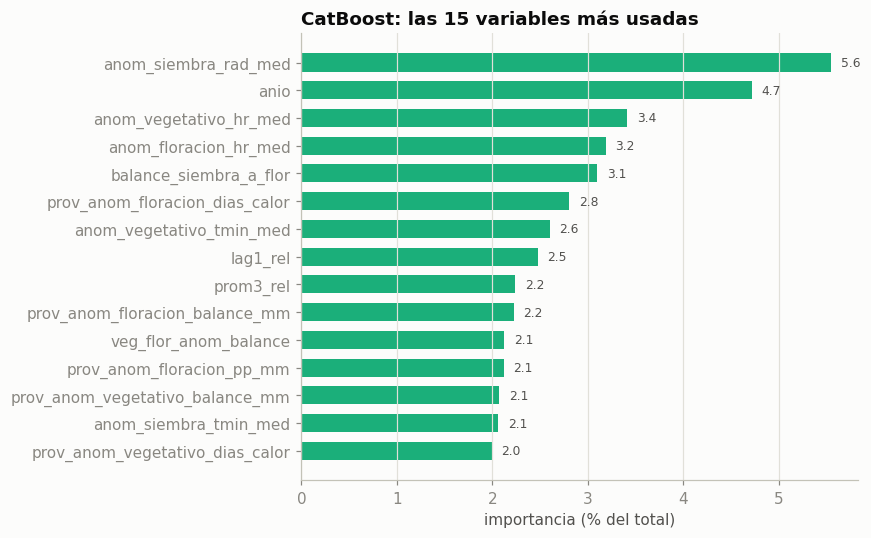

In [4]:
imp = pd.Series(cat.est_.get_feature_importance(), index=cat.features_).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
t = imp.head(15).iloc[::-1]
ax.barh(t.index, t.values, color=COLORES["CatBoost"], height=.65)
for y, v in enumerate(t.values):
    ax.text(v + .1, y, f"{v:.1f}", va="center", fontsize=8, color="#52514e")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("importancia (% del total)")
ax.set_title("CatBoost: las 15 variables más usadas")
plt.tight_layout(); plt.show()

## Error en el propio train (solo como control)

Este número **no** mide qué tan bueno es el modelo (está viendo datos que ya conoce). Sirve para controlar que el entrenamiento anduvo. La estimación honesta del error es la validación del notebook 02 (≈ 511) y, sobre todo, el test del notebook 04.

In [5]:
p_train = modelo.predict(train)
print(f"RMSE en train (optimista): {rmse(train[TARGET], p_train):.0f} kg/ha")

RMSE en train (optimista): 332 kg/ha


## Guardar el modelo

Se guarda el objeto entrenado completo con `joblib`, incluidas las piezas calculadas con el train (promedios por departamento, tendencia, escalado). La definición de las clases vive en `notebooks/comun.py`, así que para cargarlo hace falta poder importar `comun`.

In [6]:
carpeta = RAIZ / "models"
carpeta.mkdir(exist_ok=True)
ruta = carpeta / "modelo_final.joblib"
joblib.dump(modelo, ruta)

ficha = {
    "modelo": "Promedio simple ElasticNet + CatBoost (target relativo)",
    "entrenado_el": str(date.today()),
    "campanias_train": [int(train.anio.min()), int(train.anio.max())],
    "filas_train": int(len(train)),
    "momento_de_prediccion": "10 de febrero (ventanas barbecho, siembra, vegetativo, floración)",
    "hiperparametros": {"ElasticNet": HP_ELASTICNET, "CatBoost": HP_CATBOOST},
    "extras": {"ElasticNet": list(EXTRAS_LINEAL), "CatBoost": list(EXTRAS_ARBOLES)},
    "features": {"ElasticNet": en.features_, "CatBoost": cat.features_},
    "validacion_expansiva_2010_2019": {"rmse": 510.6, "mae": 408.8, "sesgo": -50.9,
                                       "rmse_sequia_2017": 538.3, "mejora_vs_media_depto_pct": 21.5},
}
(carpeta / "modelo_final.json").write_text(json.dumps(ficha, indent=2, ensure_ascii=False), encoding="utf-8")

# Control: el modelo cargado de disco predice exactamente lo mismo
cargado = joblib.load(ruta)
assert np.allclose(cargado.predict(train), p_train)
print(f"Guardado: {ruta.relative_to(RAIZ)} ({ruta.stat().st_size / 1e6:.1f} MB) y models/modelo_final.json ✔")

Guardado: models\modelo_final.joblib (1.2 MB) y models/modelo_final.json ✔
